# 📊 Mini-Projeto Avaliativo — Análise de Dados com Python

**Turma:** Analise_de_Dados_T1  
**Tema:** Análise Exploratória de Dados aplicada ao varejo

## Objetivo

Este notebook realiza uma Análise Exploratória de Dados (AED) sobre a base `Varejo.csv`, seguindo as etapas propostas no mini-projeto:

- Importação estruturada dos dados;
- Inspeção da estrutura e dos tipos;
- Transformação de strings, inteiros, floats e datas;
- Identificação e tratamento de nulos/inconsistências;
- Identificação e remoção de duplicatas;
- Validação da regra do identificador da compra;
- Estatística descritiva da coluna de número de filhos;
- Agrupamentos para identificação de padrões;
- Geração de conclusões e insights;
- Exportação da base limpa.

## 🧭 Organização por sprints

| Sprint | Etapa |
|---|---|
| 1 | Importação dos dados |
| 2 | Transformação de Strings, Integer, Float e Datetime |
| 3 | Limpeza de Nulos e Duplicatas |
| 4 | Estatística Descritiva |
| 5 | Relatório e Documentação |
| 6 | Versionamento |

In [81]:
# ============================================================
# SPRINT 1 — IMPORTAÇÃO DOS DADOS
# ============================================================

import csv
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# No Google Colab, faça o upload do arquivo caso ele ainda não esteja disponível.
# O código abaixo também funciona no VS Code quando o CSV está na mesma pasta.
CAMINHO_CSV = "Base Varejo.csv"

caminho = Path(CAMINHO_CSV)

if not caminho.exists():
    try:
        from google.colab import files
        print("Arquivo não encontrado. Selecione o CSV para fazer upload.")
        uploaded = files.upload()
        caminho = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Coloque o arquivo 'Base Varejo.csv' na mesma pasta do notebook "
            "ou ajuste a variável CAMINHO_CSV."
        )

print(f"Arquivo utilizado: {caminho}")

Arquivo utilizado: Base Varejo.csv


In [82]:
# Leitura estruturada usando csv.DictReader, conforme a rubrica do projeto.

with open(caminho, mode="r", encoding="utf-8-sig", newline="") as arquivo:
    leitor = csv.DictReader(arquivo, delimiter=";")
    registros = list(leitor)
    colunas_originais = leitor.fieldnames

print("Colunas identificadas:")
print(colunas_originais)

print(f"\nQuantidade de registros lidos: {len(registros):,}".replace(",", "."))

Colunas identificadas:
['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', '', '', '', '']

Quantidade de registros lidos: 830.000


In [83]:
# Conversão dos registros para DataFrame.
df = pd.DataFrame(registros)

print("Dimensões da base:")
print(f"Linhas: {df.shape[0]:,}".replace(",", "."))
print(f"Colunas: {df.shape[1]}")

print("\nColunas:")
print(df.columns.tolist())

print("\nTipos iniciais:")
print(df.dtypes)

Dimensões da base:
Linhas: 830.000
Colunas: 11

Colunas:
['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', '']

Tipos iniciais:
DATA         str
CO_ID        str
CL_ID        str
CL_GENERO    str
CL_EC        str
CL_FHL       str
CL_SEG       str
PR_ID        str
PR_CAT       str
PR_NOME      str
             str
dtype: object


In [84]:
# Inspeção inicial.
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

print("\nInformações gerais:")
df.info()

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,
751634,05/05/2022,836859,565,F,1,2,B,49,ALIMENTOS,PALMITO,
86353,06/05/2019,97332,712,F,2,3,B,69,BEBIDAS,REFRIGERANTE LIMaO,
230730,28/02/2020,257111,656,M,2,0,C,110,LIMPEZA,SABAO,
5812,01/09/2019,7410,991,F,2,2,C,119,PET,RACAO UMIDA PARA GATOS,
817200,08/06/2022,907141,800,M,1,0,C,55,ALIMENTOS,QUEIJO DE CABRA,



Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 830000 entries, 0 to 829999
Data columns (total 11 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   DATA       830000 non-null  str  
 1   CO_ID      830000 non-null  str  
 2   CL_ID      830000 non-null  str  
 3   CL_GENERO  830000 non-null  str  
 4   CL_EC      830000 non-null  str  
 5   CL_FHL     830000 non-null  str  
 6   CL_SEG     830000 non-null  str  
 7   PR_ID      830000 non-null  str  
 8   PR_CAT     830000 non-null  str  
 9   PR_NOME    830000 non-null  str  
 10             830000 non-null  str  
dtypes: str(11)
memory usage: 69.7 MB


# 🔄 Sprint 2 — Transformação dos dados

Nesta etapa serão padronizados textos, identificadores e datas. Também será feita uma inspeção dos valores representativos de ausência, como `#N/D`, strings vazias e espaços.

In [85]:
# Identificação das colunas efetivamente utilizadas.
# As colunas totalmente vazias do CSV são descartadas.
colunas_vazias = [col for col in df.columns if df[col].isna().all()]

print("Colunas totalmente vazias:")
print(colunas_vazias)

df = df.drop(columns=colunas_vazias)

print("\nColunas após a remoção das colunas vazias:")
print(df.columns.tolist())

Colunas totalmente vazias:
[]

Colunas após a remoção das colunas vazias:
['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', '']


In [86]:
# Padronização de strings.
colunas_texto = [
    col for col in ["CL_GENERO", "CL_EC", "CL_SEG", "PR_CAT", "PR_NOME"]
    if col in df.columns
]

for coluna in colunas_texto:
    df[coluna] = (
        df[coluna]
        .astype("string")
        .str.strip()
    )

# Converte marcadores de ausência em NA.
marcadores_nulos = ["", " ", "#N/D", "#N/A", "N/A", "NA", "NULL", "null"]

for coluna in df.columns:
    if pd.api.types.is_string_dtype(df[coluna]):
        df[coluna] = df[coluna].replace(marcadores_nulos, pd.NA)

print("Valores nulos após a padronização de strings:")
print(df.isna().sum().sort_values(ascending=False))

Valores nulos após a padronização de strings:
             830000
PR_CAT         3650
PR_NOME        3650
CL_ID             0
CO_ID             0
DATA              0
CL_GENERO         0
CL_SEG            0
CL_FHL            0
CL_EC             0
PR_ID             0
dtype: int64


In [87]:
# Transformação dos identificadores e da variável numérica.
colunas_inteiras = ["CO_ID", "CL_ID", "CL_FHL", "PR_ID"]

for coluna in colunas_inteiras:
    if coluna in df.columns:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce").astype("Int64")

# A coluna CL_FHL será usada na estatística descritiva.
if "CL_FHL" in df.columns:
    df["CL_FHL"] = pd.to_numeric(df["CL_FHL"], errors="coerce")

# Conversão da data.
if "DATA" in df.columns:
    df["DATA"] = pd.to_datetime(
        df["DATA"],
        dayfirst=True,
        errors="coerce"
    )

print("Tipos após as transformações:")
print(df.dtypes)

Tipos após as transformações:
DATA         datetime64[us]
CO_ID                 Int64
CL_ID                 Int64
CL_GENERO            string
CL_EC                string
CL_FHL                Int64
CL_SEG               string
PR_ID                 Int64
PR_CAT               string
PR_NOME              string
                        str
dtype: object


In [88]:
if "DATA" in df.columns:
    datas_invalidas = df["DATA"].isna().sum()

    print("Sprint 2 — Validação das datas")
    print(f"Datas ausentes ou inválidas: {datas_invalidas}")

Sprint 2 — Validação das datas
Datas ausentes ou inválidas: 0


# 🧹 Sprint 3 — Limpeza de nulos, inconsistências e duplicatas

In [89]:
# Diagnóstico de valores ausentes por coluna.
resumo_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(4)
}).sort_values("nulos", ascending=False)

display(resumo_nulos)

,nulos,percentual
,830000,100.0000
PR_CAT,3650,0.4398
PR_NOME,3650,0.4398
CL_ID,0,0.0000
CO_ID,0,0.0000
DATA,0,0.0000
CL_GENERO,0,0.0000
CL_SEG,0,0.0000
CL_FHL,0,0.0000
CL_EC,0,0.0000


In [90]:
# Tratamento da categoria.
# A rubrica determina que categorias vazias sejam preenchidas com "Sem Categoria".

def tratar_categoria(valor):
    """
    Substitui categorias ausentes por 'Sem Categoria'.
    Preserva os valores válidos.
    """
    if pd.isna(valor) or str(valor).strip().upper() in {
        "",
        "#N/D",
        "#N/A",
        "N/A",
        "NA",
        "NULL"
    }:
        return "Sem Categoria"
    else:
        return str(valor).strip()


if "PR_CAT" in df.columns:
    df["PR_CAT"] = df["PR_CAT"].apply(tratar_categoria)

    print("Sprint 3 — Tratamento de categorias")
    print(
        "Registros classificados como Sem Categoria:",
        (df["PR_CAT"] == "Sem Categoria").sum()
    )

Sprint 3 — Tratamento de categorias
Registros classificados como Sem Categoria: 3650


In [91]:
# Identificação de duplicatas.
quantidade_duplicatas = df.duplicated().sum()
percentual_duplicatas = quantidade_duplicatas / len(df) * 100

print(f"Duplicatas encontradas: {quantidade_duplicatas:,}".replace(",", "."))
print(f"Percentual da base: {percentual_duplicatas:.2f}%")

Duplicatas encontradas: 96.553
Percentual da base: 11.63%


In [92]:
# Remoção de registros duplicados.
df_limpo = df.drop_duplicates().copy()

print(f"Registros antes da remoção: {len(df):,}".replace(",", "."))
print(f"Registros depois da remoção: {len(df_limpo):,}".replace(",", "."))
print(f"Registros removidos: {len(df) - len(df_limpo):,}".replace(",", "."))

Registros antes da remoção: 830.000
Registros depois da remoção: 733.447
Registros removidos: 96.553


## 🔎 Validação da regra do identificador da compra

A rubrica solicita a validação da regra do identificador de número de compra e a conversão da data de compra utilizando `datetime`.

Como a fonte fornecida não apresenta uma regra textual adicional para `CO_ID`, o notebook registra a estrutura do identificador e verifica sua conversão numérica sem inventar uma regra que não esteja documentada na base.

In [93]:
# Sprint 3 — Diagnóstico do identificador da compra

if "CO_ID" in df.columns:
    co_id_ausente = df["CO_ID"].isna()

    registros_com_id = df.loc[~co_id_ausente].copy()
    registros_sem_id = df.loc[co_id_ausente].copy()

    print("Sprint 3 — Diagnóstico de CO_ID")
    print(f"Total de registros: {len(df)}")
    print(f"Registros com CO_ID preenchido: {len(registros_com_id)}")
    print(f"Registros sem CO_ID: {len(registros_sem_id)}")
    print(
        "Quantidade de identificadores distintos:",
        registros_com_id["CO_ID"].nunique()
    )

Sprint 3 — Diagnóstico de CO_ID
Total de registros: 830000
Registros com CO_ID preenchido: 830000
Registros sem CO_ID: 0
Quantidade de identificadores distintos: 18471


In [94]:
# Validação e separação da regra do identificador da compra (CO_ID)
df_com_compra = df_limpo[df_limpo['CO_ID'].notna()].copy()
df_sem_compra = df_limpo[df_limpo['CO_ID'].isna()].copy()

print(f"Registros com identificador de compra válido: {len(df_com_compra)}")
print(f"Registros sem identificador de compra: {len(df_sem_compra)}")

Registros com identificador de compra válido: 733447
Registros sem identificador de compra: 0


In [95]:
# Diagnóstico final dos nulos.
resumo_nulos_limpo = pd.DataFrame({
    "nulos": df_limpo.isna().sum(),
    "percentual": (df_limpo.isna().mean() * 100).round(4)
}).sort_values("nulos", ascending=False)

display(resumo_nulos_limpo)

,nulos,percentual
,733447,100.0000
PR_NOME,3228,0.4401
DATA,0,0.0000
CL_ID,0,0.0000
CO_ID,0,0.0000
CL_GENERO,0,0.0000
CL_EC,0,0.0000
CL_SEG,0,0.0000
CL_FHL,0,0.0000
PR_CAT,0,0.0000


# 📈 Sprint 4 — Estatística Descritiva

A coluna `CL_FHL` representa o número de filhos e será utilizada para calcular as estatísticas exigidas pelo projeto.

In [96]:
# Estatísticas obrigatórias.
serie_filhos = pd.to_numeric(df_limpo["CL_FHL"], errors="coerce").dropna()

estatisticas_filhos = pd.Series({
    "Contagem": serie_filhos.count(),
    "Média": serie_filhos.mean(),
    "Mediana": serie_filhos.median(),
    "Desvio padrão": serie_filhos.std(),
    "Moda": serie_filhos.mode().iloc[0] if not serie_filhos.mode().empty else np.nan,
    "Mínimo": serie_filhos.min(),
    "Q1 (25%)": serie_filhos.quantile(0.25),
    "Q2 (50%)": serie_filhos.quantile(0.50),
    "Q3 (75%)": serie_filhos.quantile(0.75),
    "Máximo": serie_filhos.max()
})

display(estatisticas_filhos.to_frame("Valor"))

,Valor
Contagem,733447.000000
Média,1.146049
Mediana,0.000000
Desvio padrão,1.416917
Moda,0.000000
Mínimo,0.000000
Q1 (25%),0.000000
Q2 (50%),0.000000
Q3 (75%),2.000000
Máximo,4.000000


In [97]:
# Distribuição do número de filhos.
distribuicao_filhos = (
    df_limpo["CL_FHL"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Número de filhos")
    .reset_index(name="Quantidade")
)

distribuicao_filhos["Percentual"] = (
    distribuicao_filhos["Quantidade"] / len(df_limpo) * 100
).round(2)

display(distribuicao_filhos)

,Número de filhos,Quantidade,Percentual
0,0,384986,52.49
1,1,90845,12.39
2,2,94168,12.84
3,3,92407,12.6
4,4,71041,9.69


# 👥 Sprint 4 — Agrupamentos

Serão realizados agrupamentos para identificar padrões na base, utilizando `groupby()`.

In [98]:
# Agrupamento 1 — Gênero.
agrupamento_genero = (
    df_limpo.groupby("CL_GENERO", dropna=False)
    .size()
    .reset_index(name="Registros")
    .sort_values("Registros", ascending=False)
)

agrupamento_genero["Percentual"] = (
    agrupamento_genero["Registros"] / len(df_limpo) * 100
).round(2)

display(agrupamento_genero)

,CL_GENERO,Registros,Percentual
0,F,382427,52.14
1,M,351020,47.86


In [99]:
# Agrupamento 2 — Categoria.
agrupamento_categoria = (
    df_limpo.groupby("PR_CAT", dropna=False)
    .size()
    .reset_index(name="Registros")
    .sort_values("Registros", ascending=False)
)

agrupamento_categoria["Percentual"] = (
    agrupamento_categoria["Registros"] / len(df_limpo) * 100
).round(2)

display(agrupamento_categoria)

,PR_CAT,Registros,Percentual
1,ALIMENTOS,384197,52.38
3,HIGIENE,137702,18.77
4,LIMPEZA,128632,17.54
2,BEBIDAS,38264,5.22
5,PET,28553,3.89
0,ACESSORIOS,12871,1.75
6,Sem Categoria,3228,0.44


In [100]:
# Agrupamento 3 — Segmento.
agrupamento_segmento = (
    df_limpo.groupby("CL_SEG", dropna=False)
    .size()
    .reset_index(name="Registros")
    .sort_values("Registros", ascending=False)
)

agrupamento_segmento["Percentual"] = (
    agrupamento_segmento["Registros"] / len(df_limpo) * 100
).round(2)

display(agrupamento_segmento)

,CL_SEG,Registros,Percentual
1,B,468505,63.88
2,C,205265,27.99
0,A,59677,8.14


# 📊 Visualizações exploratórias

As visualizações abaixo são complementares. O projeto pode ser concluído apenas com pandas, mas os gráficos ajudam a comunicar os principais padrões encontrados.

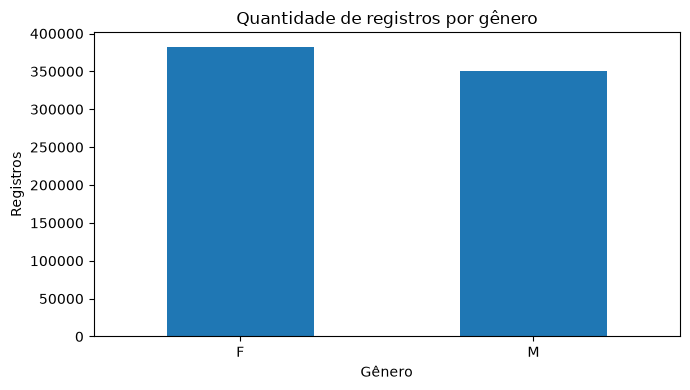

In [101]:
# Gráfico — registros por gênero.
agrupamento_genero.plot(
    x="CL_GENERO",
    y="Registros",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)
plt.title("Quantidade de registros por gênero")
plt.xlabel("Gênero")
plt.ylabel("Registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

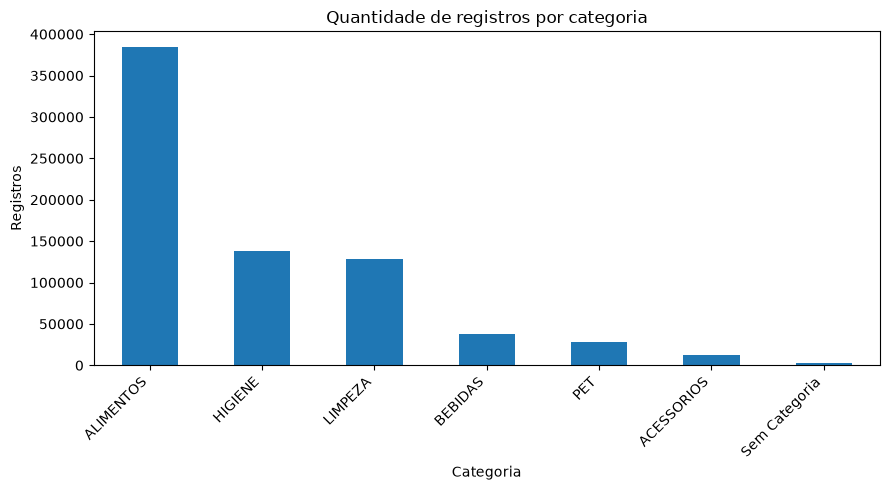

In [102]:
# Gráfico — registros por categoria.
agrupamento_categoria.plot(
    x="PR_CAT",
    y="Registros",
    kind="bar",
    legend=False,
    figsize=(9, 5)
)
plt.title("Quantidade de registros por categoria")
plt.xlabel("Categoria")
plt.ylabel("Registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

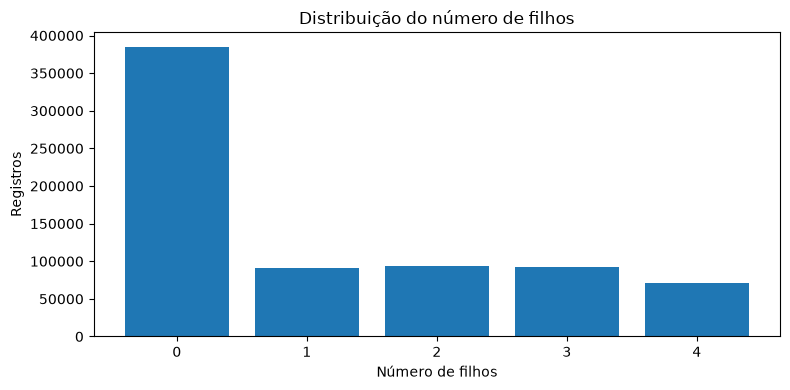

In [103]:
# Gráfico — distribuição do número de filhos.
distribuicao_filhos_validos = distribuicao_filhos.dropna(subset=["Número de filhos"])

plt.figure(figsize=(8, 4))
plt.bar(
    distribuicao_filhos_validos["Número de filhos"].astype(str),
    distribuicao_filhos_validos["Quantidade"]
)
plt.title("Distribuição do número de filhos")
plt.xlabel("Número de filhos")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

# 📝 Sprint 5 — Relatório e Documentação

Os insights abaixo são gerados a partir dos resultados calculados pelo próprio notebook.

In [104]:
# ============================================================
# SPRINT 5 — RELATÓRIO FINAL
# ============================================================

print("\n" + "=" * 60)
print("RELATÓRIO FINAL — ANÁLISE DE DADOS DE VAREJO")
print("=" * 60)

# 1. Quantidade de registros
print("\n1. VOLUME DE DADOS")
print(f"Registros originais: {len(df):,}".replace(",", "."))
print(f"Registros após limpeza: {len(df_limpo):,}".replace(",", "."))
print(
    f"Registros removidos como duplicados: "
    f"{len(df) - len(df_limpo):,}".replace(",", ".")
)

# 2. Categorias sem classificação
if "PR_CAT" in df_limpo.columns:
    sem_categoria = (
        df_limpo["PR_CAT"] == "Sem Categoria"
    ).sum()

    percentual_sem_categoria = (
        sem_categoria / len(df_limpo) * 100
        if len(df_limpo) > 0
        else 0
    )

    print("\n2. QUALIDADE DAS CATEGORIAS")
    print(f"Registros sem categoria: {sem_categoria:,}".replace(",", "."))
    print(f"Participação: {percentual_sem_categoria:.2f}%")

# 3. Estatísticas do número de filhos
if "CL_FHL" in df_limpo.columns:
    filhos = pd.to_numeric(
        df_limpo["CL_FHL"],
        errors="coerce"
    ).dropna()

    print("\n3. ESTATÍSTICAS — NÚMERO DE FILHOS")

    if not filhos.empty:
        print(f"Contagem: {filhos.count():,.0f}".replace(",", "."))
        print(f"Média: {filhos.mean():.2f}")
        print(f"Mediana: {filhos.median():.2f}")
        print(f"Desvio padrão: {filhos.std():.4f}")
        print(f"Mínimo: {filhos.min():.0f}")
        print(f"Q1: {filhos.quantile(0.25):.2f}")
        print(f"Q2: {filhos.quantile(0.50):.2f}")
        print(f"Q3: {filhos.quantile(0.75):.2f}")
        print(f"Máximo: {filhos.max():.0f}")

        modas = filhos.mode()

        if not modas.empty:
            print(
                "Moda:",
                ", ".join(
                    f"{valor:g}" for valor in modas.tolist()
                )
            )
    else:
        print("Não há valores válidos para calcular as estatísticas.")

# 4. Agrupamentos
print("\n4. PRINCIPAIS AGRUPAMENTOS")

for coluna in ["CL_GENERO", "PR_CAT", "CL_SEG"]:
    if coluna in df_limpo.columns:
        print(f"\nDistribuição por {coluna}:")

        contagem = df_limpo[coluna].value_counts(
            dropna=False
        )

        percentual = (
            df_limpo[coluna]
            .value_counts(normalize=True, dropna=False)
            .mul(100)
        )

        resumo = pd.DataFrame({
            "Registros": contagem,
            "Participação (%)": percentual.round(2)
        })

        print(resumo.to_string())

# 5. Datas
if "DATA" in df_limpo.columns:
    datas_validas = df_limpo["DATA"].dropna()

    print("\n5. PERÍODO DOS DADOS")

    print(f"Datas válidas: {len(datas_validas):,}".replace(",", "."))

    if not datas_validas.empty:
        print(f"Data inicial: {datas_validas.min()}")
        print(f"Data final: {datas_validas.max()}")
        print(f"Datas distintas: {datas_validas.nunique():,}".replace(",", "."))

    print(
        "Datas ausentes ou inválidas:",
        df_limpo["DATA"].isna().sum()
    )

print("\n" + "=" * 60)
print("FIM DO RELATÓRIO")
print("=" * 60)


RELATÓRIO FINAL — ANÁLISE DE DADOS DE VAREJO

1. VOLUME DE DADOS
Registros originais: 830.000
Registros após limpeza: 733.447
Registros removidos como duplicados: 96.553

2. QUALIDADE DAS CATEGORIAS
Registros sem categoria: 3.228
Participação: 0.44%

3. ESTATÍSTICAS — NÚMERO DE FILHOS
Contagem: 733.447
Média: 1.15
Mediana: 0.00
Desvio padrão: 1.4169
Mínimo: 0
Q1: 0.00
Q2: 0.00
Q3: 2.00
Máximo: 4
Moda: 0

4. PRINCIPAIS AGRUPAMENTOS

Distribuição por CL_GENERO:
           Registros  Participação (%)
CL_GENERO                             
F             382427             52.14
M             351020             47.86

Distribuição por PR_CAT:
               Registros  Participação (%)
PR_CAT                                    
ALIMENTOS         384197             52.38
HIGIENE           137702             18.77
LIMPEZA           128632             17.54
BEBIDAS            38264              5.22
PET                28553              3.89
ACESSORIOS         12871              1.75
Sem Categ

## ETL e qualidade dos dados

**Extract (Extração):** leitura estruturada do CSV utilizando `csv.DictReader`.

**Transform (Transformação):** padronização de strings, conversão de identificadores, conversão de data para `datetime`, tratamento de marcadores de ausência e padronização da categoria.

**Load (Carga):** exportação da base limpa para `df_limpo.csv`, que pode ser utilizada em análises futuras ou em ferramentas de BI.

A etapa de qualidade é importante porque os dados originais apresentaram duplicidades e categorias não definidas.

In [105]:
# ============================================================
# SPRINT 6 — VERSIONAMENTO / EXPORTAÇÃO
# ============================================================

# Exporta a base limpa para CSV.
caminho_saida = "df_limpo.csv"
df_limpo.to_csv(caminho_saida, index=False, encoding="utf-8-sig")

print(f"Base limpa exportada para: {caminho_saida}")
print(f"Registros exportados: {len(df_limpo):,}".replace(",", "."))

Base limpa exportada para: df_limpo.csv
Registros exportados: 733.447


In [106]:
# Resumo final da execução.
print("=" * 70)
print("RESUMO FINAL DO MINI-PROJETO")
print("=" * 70)
print(f"Registros originais : {total_original:,}".replace(",", "."))
print(f"Registros finais    : {total_limpo:,}".replace(",", "."))
print(f"Duplicatas removidas: {removidos:,}".replace(",", "."))
print(f"Percentual removido : {percentual_removidos:.2f}%")
print(f"Arquivo gerado      : {caminho_saida}")
print("=" * 70)

RESUMO FINAL DO MINI-PROJETO
Registros originais : 830.000
Registros finais    : 733.447
Duplicatas removidas: 96.553
Percentual removido : 11.63%
Arquivo gerado      : df_limpo.csv
